In [1]:
import os
import sys
import networkx as nx

module_path = os.path.abspath(os.path.join('..'))

if module_path not in sys.path:
    sys.path.append(module_path)

# Notes

In [2]:
from pathlib import Path

from iso639 import Language
from matplotlib import pyplot as plt
from matplotlib import ticker
import numpy as np
import polars as pl

OUT_PATH: Path = Path("../out")
DATA_PATH: Path = Path("../data/processed/words")
COLOR: str = "darkslategrey"

langs = pl.read_parquet(OUT_PATH / "languages.parquet")
langs_scraped = [f.stem for f in DATA_PATH.glob("*.parquet")]
words = pl.read_parquet(OUT_PATH / "words.parquet")
cols = set(langs.columns).intersection(words.columns)
words = words.join(langs, on=list(cols)).with_columns(pl.col("word").str.len_chars().alias("n_char"))
sylls = pl.read_parquet(OUT_PATH / "syllables.parquet").join(langs, on=list(cols)).with_columns(n_phon = pl.col("syll").str.len_chars())



def iso639_p3_to_name(p3: str):
    try:
        lang = Language.from_part3(p3)
        return str(lang.name)
    except (LookupError, ValueError, AttributeError):
        return


## Outline

## Introduction

### Syllables are a critical lingusitic unit during early language acquisition

Speech is made of hierarchically organised, discrete linguistic units (e.g., phonemes, syllables, words, phrases). Syllables are a privileged linguistic unit in speech processing, particularly during early language acquisition: newborns preferentially chunk the speech signal into syllable-sized units [bijeljac-babic1993how]. This is remarkable, given they have accumulated relatively limited linguistic experience. The mechanisms underlying syllable identification are still unclear.

### The Sonority Sequencing Principle (SSP) may provide cues to syllable identification

There is some evidence that, at birth, humans are sensitive to certain constraints on syllabic structure. One of them is the Sonority Sequencing Principle (SSP), which constrains the order of the segments inside a syllable based on sonority. Sonority is a phonological feature that describes the perceptual loudness of a segment relative to neighbouring segments. The SSP states that each syllable displays a unique peak of sonority in the nucleus, and that sonority rises unidirectionally from the syllable margins toward the nucleus [parker2008sounda].

Sonority scales have been developed so that different segment classes are assigned some scalar, ordered sonority score, following available literature of cross-linguistic phonology [see jany2007universal for an acoustic grouding of this sonority hierarchy, based on intensity]. By assigning numeric sonority values to specific segments, syllables can be classified as following or violating the SSP. clements1990role proposes the following sonority hierarchy:

> vowels > glides > liquids > nasals > obstruents

### Newborns are sensitive to (violations of) the SSP

gomez2014language showed in newborns that hearing SSP-following syllables (e.g., *bran*) elicits different brain haemodynamic responses compared to SSP-violating syllables (e.g., *lbif*), suggesting that newborns, who have not yet acquired extensive experience with the phonological contraints of their native language, are already sensitive to violations of the SSP. 

Such early bias toward certain syllabic structures would provide humans with an available mechanism to detect syllables in the continuous speech stream at the earliest stages of language acquisition.

### Is the SSP a linguistic universal?

The SSP has been long claimed to be a linguistic universal, on the grounds of SSP-following syllables being preferred over SSP-violating syllables across most languages. For instance, parker2017sounding reported evidence from 275 experimental works on a typologically diverse list of 75 distinct languages, and reports that 63% of the studies suggest that sonority plays a relevant role for accounting for the results, and 22% provide inconclusive evidence, and 15% provide negative evidence for such a relevant role of sonority.

The universality of the SSP would place this principle as one of the few cues for speech segmentation available since birth  for *all* humans to exploit in order to identify syllables in the speech stream during their earliest states of language acquisition, before language-specific constraints to sound sequences (e.g., phonotactics) are available.

The universal status of the SSP is however a matter of debate. One argument against such universality is that violations of the SSP are common across may (if not all) languages. For instance, the /st-, -ts/ consonant clusters violate the SSP when at syllabic onset or at coda (e.g., *street*, *ticks*), respectively. This violation of the SSP has been attested in many langugaes including English [kawasaki1997alternatives]. Some languages, like Russian, are known for allowing fairly complex consonant clusters at syllabic onset that violate the SSP (e.g., взгляд (*vzglyad* [glance]) [halle1971sound; ito1982syllable].

More recent accounts of linguistic universals [e.g., Optimality Theory, prince2004optimalitya] propose a softer understanding of the term "universal", such that linguistic universals represent overall preferences toward certain linguistic structures across languages, instead of hard ON/OFF constraints. Under this account, the role of the SSP as a universally available cue for syllabification becomes a statistical question [e.g., frisch2015preliminary]: how often do syllables in different languages abide by the SSP?

The aim of the present paper is to provide empirical estimates of the prevalence of the SSP in a fairly representative sample of languages.

## Research questions

1) What proportion of the syllabic repertoire of a language follows the SSP?

What is the empirical proportion of SSP-following and SSP-violating syllables in each language?

2) Are SSP-following syllables more frequent in the lexicon of each language, compared to SSP-violating syllables?
    2.1) In adult-directed lexical frequencies?
    2.2) In infant-directed lexical frequencies?
    2.3) In the infant lexicon?

Estimating SSP prevalence on the phonemic repertoire assumes that all syllables appear with identical frequency in the language they belong to. This is not necessarily the case. For instance, /ka/ probably appears more often than /gla/. If SSP-following syllables appear in speech more often than SSP-violating syllables, the SSP prevalence estimate likely underestimates the true value of the parameter (or overestimates, in the opposite situation).

3) Does under/over-representation of some languages in the available data bias the estimation of SSP prevalence?

We do not have access to the full syllabic repertoire of each language. Available syllables from languages are the result of convenience samples (e.g., in Wiktionary, word entries are created by volunteers). The number of entries from each language, the amount of detail with which they are entered, and the type of words that are entered, varies systematically across languages. This might bias the estimates. For instance, if SSP-violating syllables are less frequent than SSP-following syllables in the lexicon of a language, and less frequent words are less likely to enter Wiktionary by volunteers, then the observed prevalence o fSSP for that language likely overestimates the prevalence of SSP-following languages.

## Method

### Data

1) Scrape word entries with phonological transcriptions from [Wiktionary](https://www.wiktionary.org/). Why Wiktionary?
    - Diversity: pronunciations from over 900 languages, 165 of which have at least 100 phonological transcriptions available.
    - Extensiveness: Contains a total of  1.7 million phonological entries.
    - Open-source, free.
    - Available tools for scraping: wikipron (Python) [lee2020massively]
    - Lexicon-like: preserves syllable counts across words from the same language.
2) Syllabify pronunciations:
    2.1) Use explicit syllable boundary markers if available (e.g., /ˈtaw.lə/).
    2.2) Use implicity syllable boundaries if available, like primary and secondary stress markers (e.g., /kaˈxõn/, /prəˌnʌnsiˈeɪʃən/)
    2.3) In the absence of syllabic markers, assume the word is monosyllabic (e.g., /ˈklaws/, /ˈkasə/).
    2.4) Filter our resulting syllables with more than one vocalic cluster (assumed to be bisyllabic) (e.g., /ˈklaws/ good, /ˈkasə/ bad)
3) Evaluate if syllable follows the SSP:
    3.1) Transform syllables into sonority scores (`wikipron`)
    3.2) Evaluate if syllable has exactly one peak of sonority:
        - `True`: SSP-following
        - `False`: SSP-violating

### Data analysis

#### 1) What proportion of the syllabic repertoire of a language follows the SSP?

1) Remove duplicated syllables from each language dataset.
2) Aggregate across syllables from each language dataset to estimate the proportion of syllables that follow/violate the SSP.
3) Build a multilevel model that provides a global and a group-specific (i.e. language-specific) estimate of the porportion of SSP-following syllables in the syllabic repertoire of each language in the dataset.
    3.1) Report **global estimate** as an approximation to the prevalence of SSP across languages with several degrees of uncertainty.
    3.2) Report **language-specific estimates** for consultation in a table.

#### 2) Are SSP-following syllables more frequent in the lexicon of each language, compared to SSP-violating syllables?

1) Create a *syllabic frequency* measure that accounts for how often a syllable appears across words in each language, and that adjusts this prevalence by the lexical frequency of the words it appears in [see frisch2015preliminary for a similar approach].
    1.1) For each language dataset, get the lexical frequency of each word in a lexical frequency database for that language.
    1.2) *Syllabic frequency*: Add up the lexical frequency of the words each syllable appears in.
2) Fit a model (same basic stucture as before) that includes the *syllabic frequency* predictor, and compare its regression coefficient against zero (perhaps specifying a ROPE).


## Languages

### Number of available languages

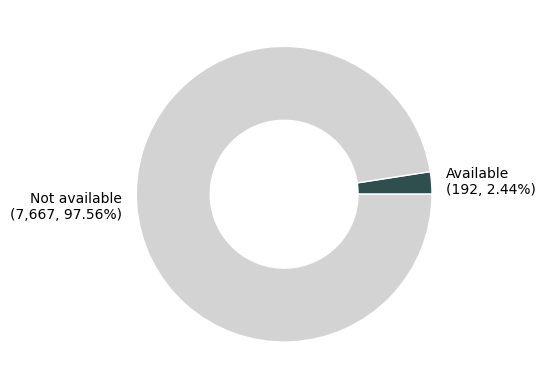

In [3]:
data = (
    langs.with_columns(
        status=pl.when(pl.col("iso639p3code").is_in(words["iso639p3code"].to_list()))
        .then(pl.lit("Available"))
        .otherwise(pl.lit("Not available"))
    )
    .group_by("status")
    .len("n")
)

values = data["n"]
labels = [f"{s}\n({n:,}, {n / sum(values):.2%})" for s, n in data.iter_rows()]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=[COLOR, "lightgrey"],
)


### Language families

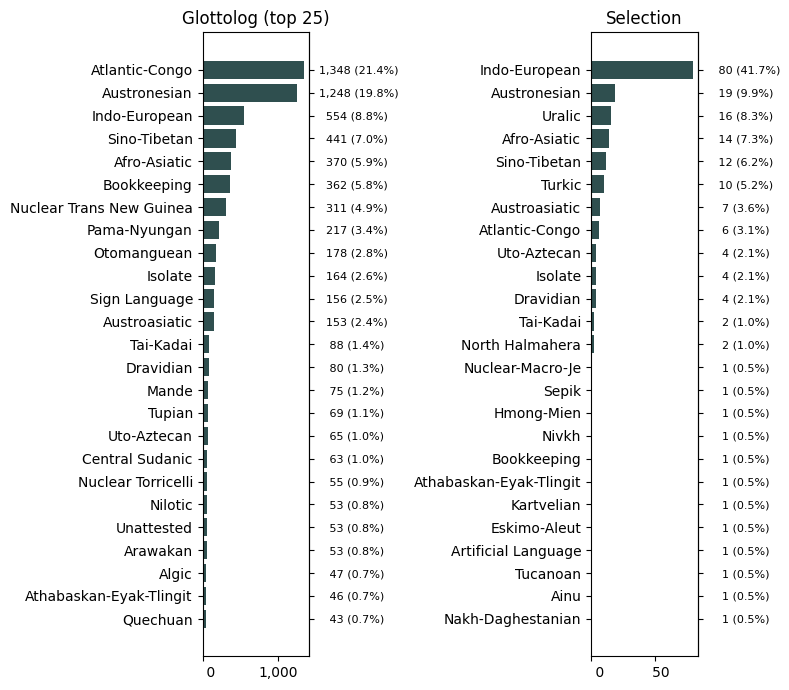

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 7))
n_fams = len(words.unique("family_id"))
for d, t, ax in zip([langs, words], [f"Glottolog (top {n_fams})", "Selection"], axes):
    d = d.unique("iso639p3code").group_by("family_id").len("n").sort("n")
    if len(d) > 100:
        d = d.top_k(k=n_fams, by="n").sort("n")

    p = ax.barh(d["family_id"], d["n"], color=COLOR)
    
    ticks = ax.get_yticks()
    labels = [f"{n:5,d} ({n / sum(d['n']):.1%})" for n in d["n"]]
    ax2 = ax.secondary_yaxis('right')
    ax2.set_yticks(ticks)
    ax2.set_yticklabels(labels)
    ax2.tick_params(axis="y", labelsize=8)
    ax.set_title(t)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))

fig.tight_layout()


Text(-0.15, 1, 'Most languages')

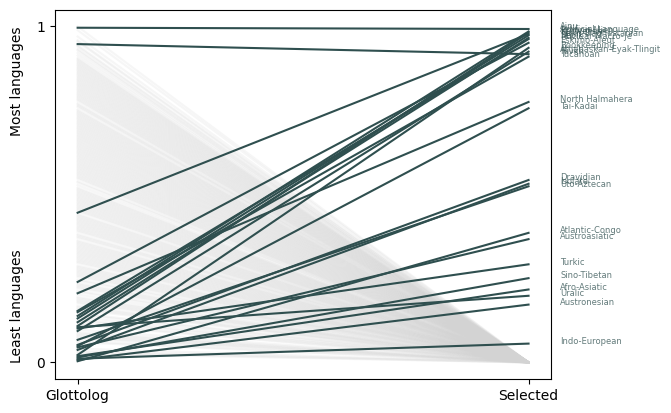

In [5]:
cols = ["iso639p3code", "family_id"]
data = [
    langs.select(cols).with_columns(source=pl.repeat("Glottolog", len(langs))),
    words.select(cols)
    .unique("iso639p3code")
    .with_columns(source=pl.repeat("Selected", pl.len())),
]
data = (
    pl.concat(data)
    .group_by(["source", "family_id"])
    .len("n")
    .with_columns(
        rank=pl.col("n")
        .over("source")
        .rank("ordinal", descending=True)
        .cast(pl.Float64)
        / pl.len()
    )
    .sort("rank")
    .pivot(index="family_id", on="source", values="rank")
    .rename(lambda x: x.lower())
    .fill_null(0)
    .with_columns((pl.col("glottolog") - pl.col("selected")).alias("diff"))
    .with_columns(
        diff=(pl.col("diff") - pl.col("diff").min())
        / (pl.col("diff").max() - pl.col("diff").min())
    )
    .sort("diff", descending=True)
)

fig, ax = plt.subplots(1, 1)
for f, g, s, d in data.iter_rows(named=False):
    ax.plot(
        ["Glottolog", "Selected"],
        [g, s],
        c="lightgrey" if s == 0 else COLOR,
        alpha=0.2 if s == 0 else 1,
    )
    if s != 0:
        ax.text(1.07, s, f, ha="left", fontsize=6, alpha=0.75, color=COLOR)
ax.set_yticks([0, 1])
ax.text(x=-0.15, y=0, s="Least languages", rotation=90, va="bottom")
ax.text(x=-0.15, y=1, s="Most languages", rotation=90, va="top")


## Words

### Number of words per language

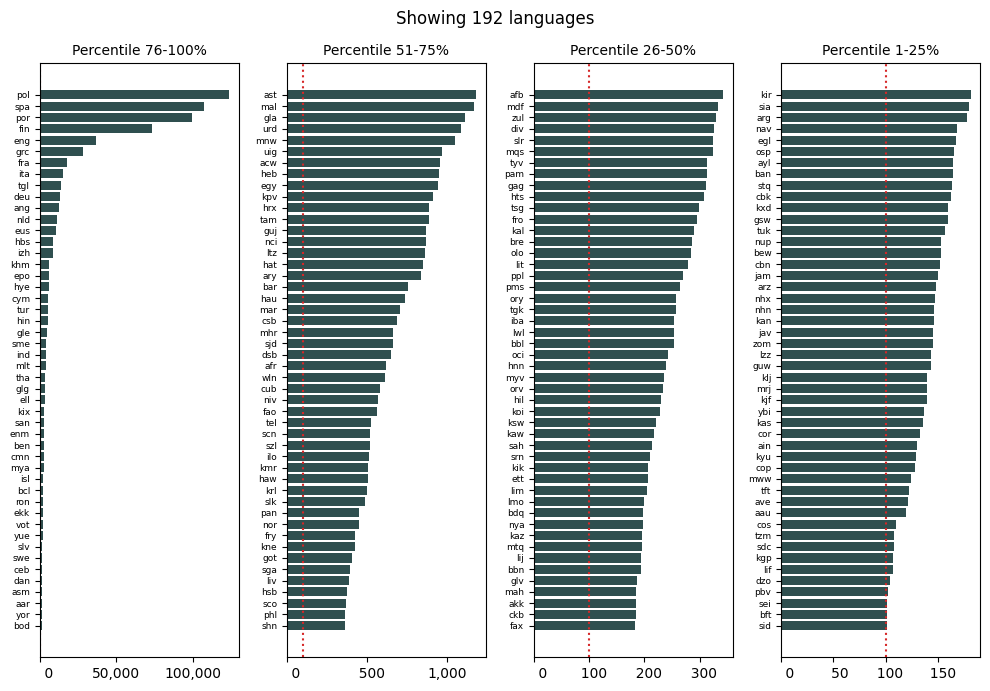

In [6]:
data = (
    words.group_by("iso639p3code")
    .len("n")
    .with_columns(
        qtile=pl.col("n").qcut(
            [0.25, 0.50, 0.75], labels=["1-25%", "26-50%", "51-75%", "76-100%"]
        )
    )
).sort("qtile", descending=True)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    lang, n, q = d.sort("n").iter_columns()
    ax = axes[i]
    ax.barh(lang, n, color=COLOR)
    ax.set_title(f"Percentile {q[0]}", fontsize=10)
    
    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.axvline(100, linestyle="dotted", color="tab:red")
fig.suptitle(f"Showing {len(data)} languages")
fig.tight_layout()

### Word lengths

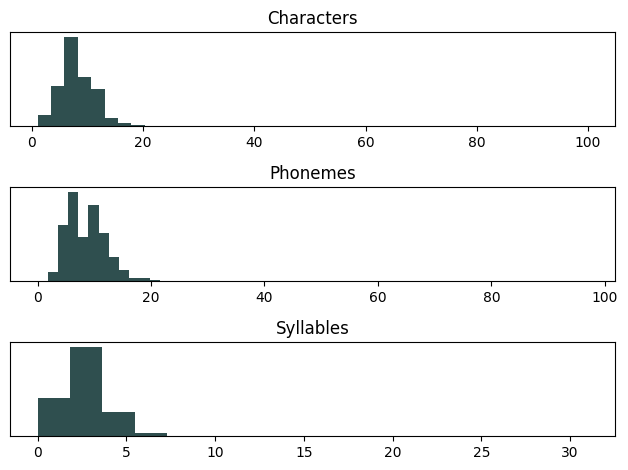

In [7]:
vars = {"char": "Characters", "phon": "Phonemes", "syll": "Syllables"}

fig, axes = plt.subplots(len(vars), 1)
for i, (var, label) in enumerate(vars.items()):
    x=words[f"n_{var}"]
    ax = axes[i]
    ax.hist(x, bins=len(set(x)), color=COLOR)
    ax.set_title(label)
    ax.set_yticks([])
fig.tight_layout()


### By number of characters

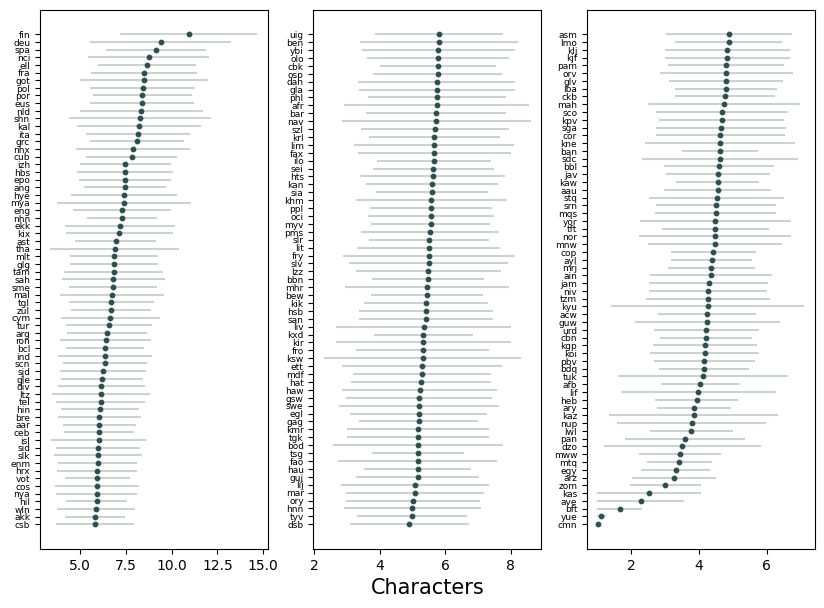

In [8]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_char").mean(), std=pl.col("n_char").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Characters", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)

#### By number of phonemes

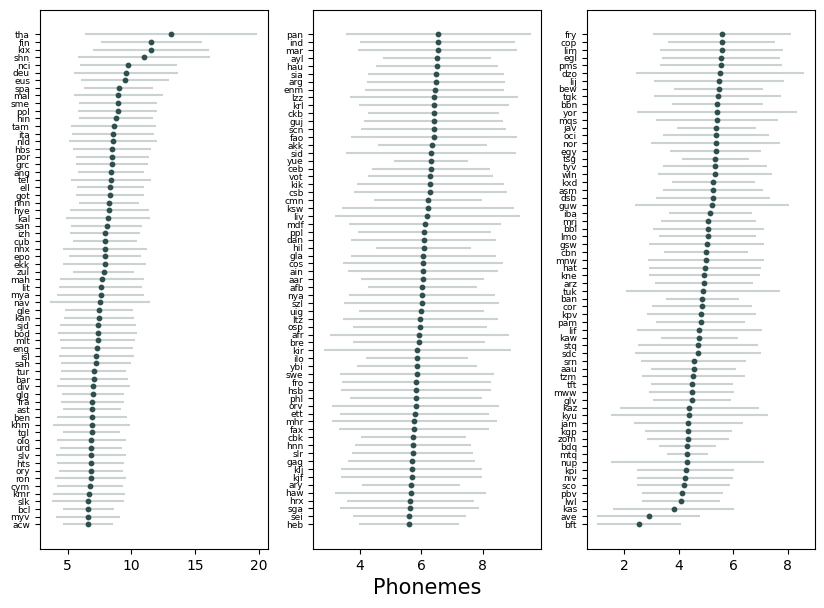

In [9]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_phon").mean(), std=pl.col("n_phon").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Phonemes", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)


### By number of syllables

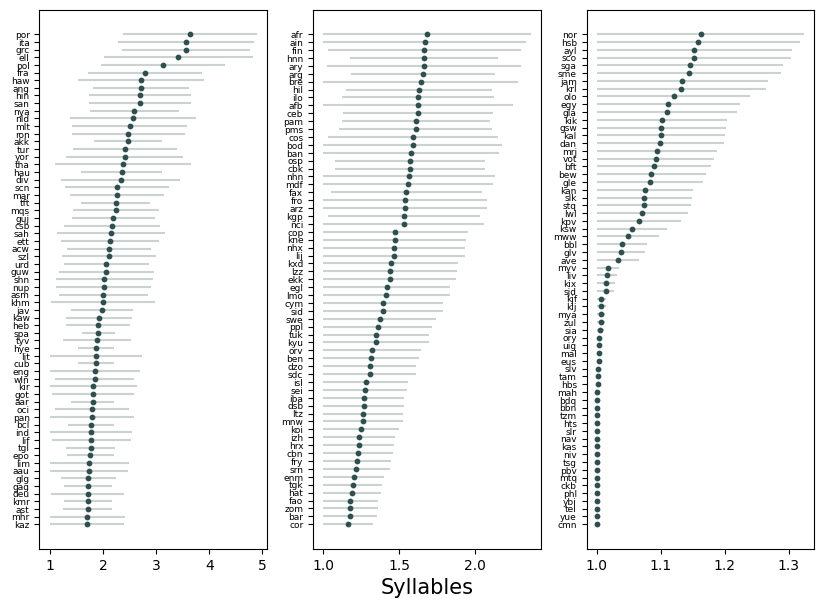

In [10]:
data = (
    words.group_by(["iso639p3code"])
    .agg(mean=pl.col("n_syll").mean(), std=pl.col("n_syll").std())
    .with_columns(
        qtile=pl.col("mean").qcut(
            [0.33, 0.66], labels=["Top 3rd", "Mid 3rd", "Bottom 3rd"]
        )
    )
    .sort(["qtile", "mean"])
)

# TODO: compare chars, phons and sylls from each language individually
n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    limit = 1
    dist_to_limit = d["mean"] - limit
    yerr_clipped = np.minimum(d["std"], dist_to_limit)

    ax = axes[i]
    ax.errorbar(
        d["mean"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    if i==n_qtiles//2:
        ax.set_xlabel("Syllables", fontsize=15)
    ax.scatter(d["mean"], d["iso639p3code"], s=10, c=COLOR)
    ax.tick_params(axis="y", labelsize=6.5)


### Word length against number of words

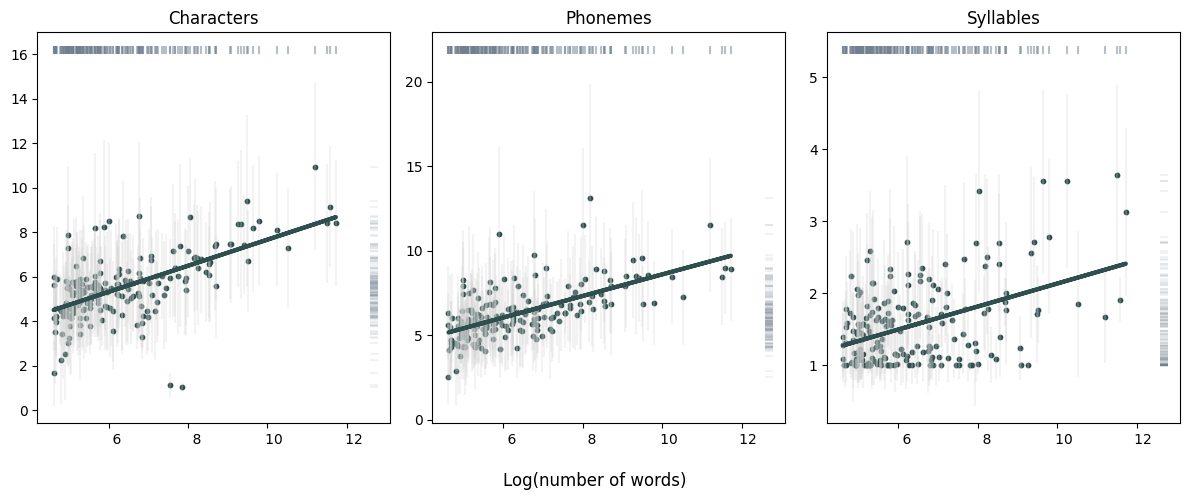

In [11]:
data = (
    words
    .group_by(["iso639p3code"])
    .agg(
        mean_phonemes=pl.col("n_phon").mean(),
        std_phonemes=pl.col("n_phon").std(),
        mean_characters=pl.col("n_char").mean(),
        std_characters=pl.col("n_char").std(),
        mean_syllables=pl.col("n_syll").mean(),
        std_syllables=pl.col("n_syll").std(),
        n=pl.len().log(),
    )
)

units = ["characters", "phonemes", "syllables"]
fig, (axes) = plt.subplots(1, len(units), figsize=(12, 5))

for i, var in enumerate(units):
    x = data["n"]
    coef = np.polyfit(x.to_list(), data[f"mean_{var}"].to_list(), 1)
    fit = np.poly1d(coef)
    ax = axes[i]
    ax.errorbar(
        x,
        data[f"mean_{var}"],
        yerr=data[f"std_{var}"],
        c="lightgrey",
        alpha=1 / 4,
        linestyle="None",
    )
    ax.plot(x, fit(x), lw=3, c=COLOR)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.scatter(x, data[f"mean_{var}"], s=10, c=COLOR)
    ax.set_title(f"{var.title()}")
    _, ymax = ax.get_ylim()
    ax.scatter(data["n"], [ymax + (ymax*0.05)] * len(data), marker="|", c="slategrey", alpha= 0.5)

    _, xmax = ax.get_xlim()
    ax.scatter([xmax + (xmax * 0.05)]*len(data), data[f"mean_{var}"],  marker="_", c="slategrey", alpha = 0.1)
fig.supxlabel("Log(number of words)")
fig.tight_layout()

## Lexical frequencies

### Available lexical frequencies

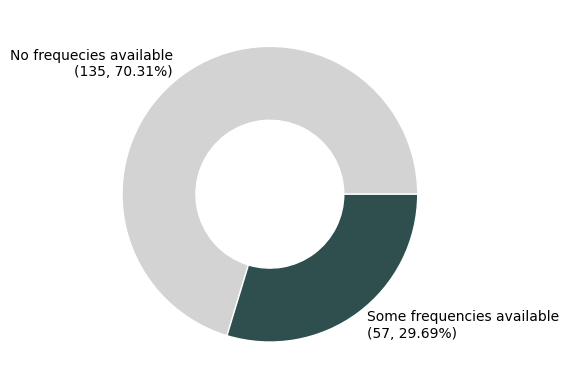

In [12]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_null().sum().alias("n_missing"), n=pl.len())
    .with_columns(prop_missing=pl.col("n_missing") / pl.col("n")).sort("prop_missing", descending=True)
    .with_columns(availability =pl.when(pl.col("prop_missing")==1).then(pl.lit("No frequecies available")).otherwise(pl.lit("Some frequencies available")))
    .group_by("availability")
    .len("n")
)

values = data["n"]
labels = [f"{s}\n({n:,}, {n / sum(values):.2%})" for s, n in data.iter_rows()]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

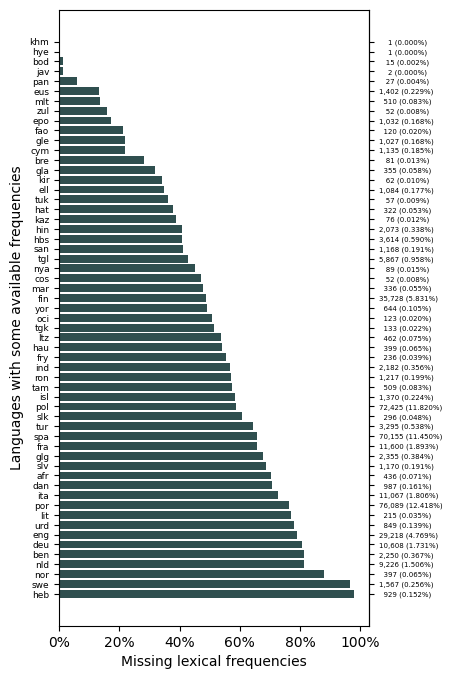

In [13]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_not_null().sum().alias("n_obs"), n=pl.len())
    .with_columns(prop_obs=pl.col("n_obs") / pl.col("n")).sort("prop_obs", descending=True)
    .filter(pl.col("prop_obs")!=0)
)

fig, ax = plt.subplots(1, 1, figsize=(4, 8))
ax.barh(data["iso639p3code"], data["prop_obs"], color=COLOR)
ax.tick_params(axis="y", labelsize=6.5)
ax.set_ylabel("Languages with some available frequencies")
ax.set_xlabel("Missing lexical frequencies")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

ticks = ax.get_yticks()
labels = [f"{n:5,d} ({n / sum(data['n']):.3%})" for n in data["n_obs"]]
ax2 = ax.secondary_yaxis('right')
ax2.set_yticks(ticks)
ax2.set_yticklabels(labels, ha="left")
ax2.tick_params(axis="y", labelsize=5)


### Proportion of observed frequencies by number of observations

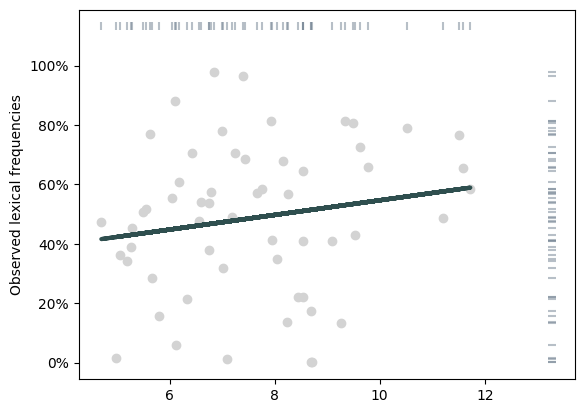

In [14]:
data = (
    words.select(["iso639p3code", "freq"])
    .group_by("iso639p3code")
    .agg(pl.col("freq").is_not_null().sum().alias("n_obs"), n=pl.len())
    .with_columns(prop_obs=pl.col("n_obs") / pl.col("n"), n = pl.col("n").log()).sort("prop_obs", descending=True)
    .filter(pl.col("prop_obs")!=0)
)

fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"],  data["prop_obs"], c="lightgrey")
coef = np.polyfit(data["n"].to_list(), data["prop_obs"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_ylabel("Observed lexical frequencies")
ax.set_label("Log(Number of words)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

_, ymax = ax.get_ylim()
ax.scatter(data["n"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha= 0.5)

_, xmax = ax.get_xlim()
ax.scatter([xmax + (xmax * 0.1)]*len(data), data["prop_obs"],  marker="_", c="slategrey", alpha = 0.5)



### Distribution of lexical frequencies

### Distribution of lexical frequencies by language

Text(0.5, 0, 'Lexical frequency (Zipf)')

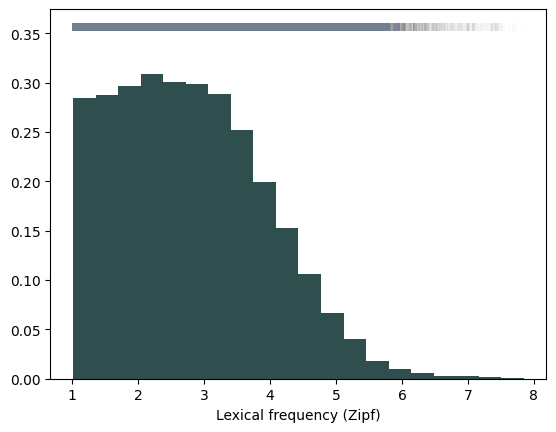

In [15]:
data = words.select(["iso639p3code", "word", "freq"]).drop_nulls()

fig, ax = plt.subplots(1, 1)
p = ax.hist(data["freq"], density=True, histtype="stepfilled", bins=20, lw=3, color=COLOR)
_, ymax = ax.get_ylim()
ax.scatter(data["freq"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha = 0.005)

ax.set_xlabel("Lexical frequency (Zipf)")

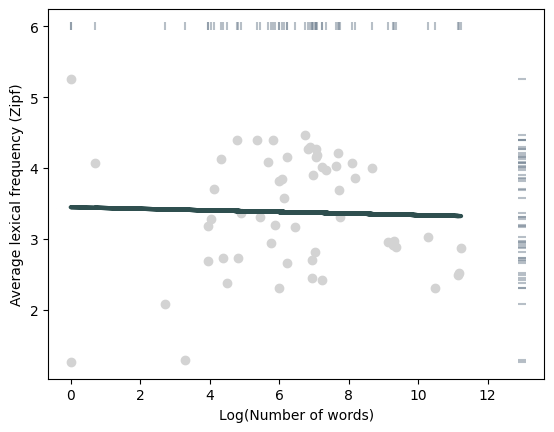

In [16]:
data = words.select(["iso639p3code", "word", "freq"]).drop_nulls().group_by("iso639p3code").agg(pl.col("freq").mean(), n=pl.len().log())

fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"], data["freq"], color="lightgrey")
coef = np.polyfit(data["n"].to_list(), data["freq"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_xlabel("Log(Number of words)")
ax.set_ylabel("Average lexical frequency (Zipf)")

_, ymax = ax.get_ylim()
ax.scatter(data["n"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha=0.5)

_, xmax = ax.get_xlim()
ax.scatter([xmax + (xmax * 0.1)]*len(data), data["freq"],  marker="_", c="slategrey", alpha=0.5)



## Syllables

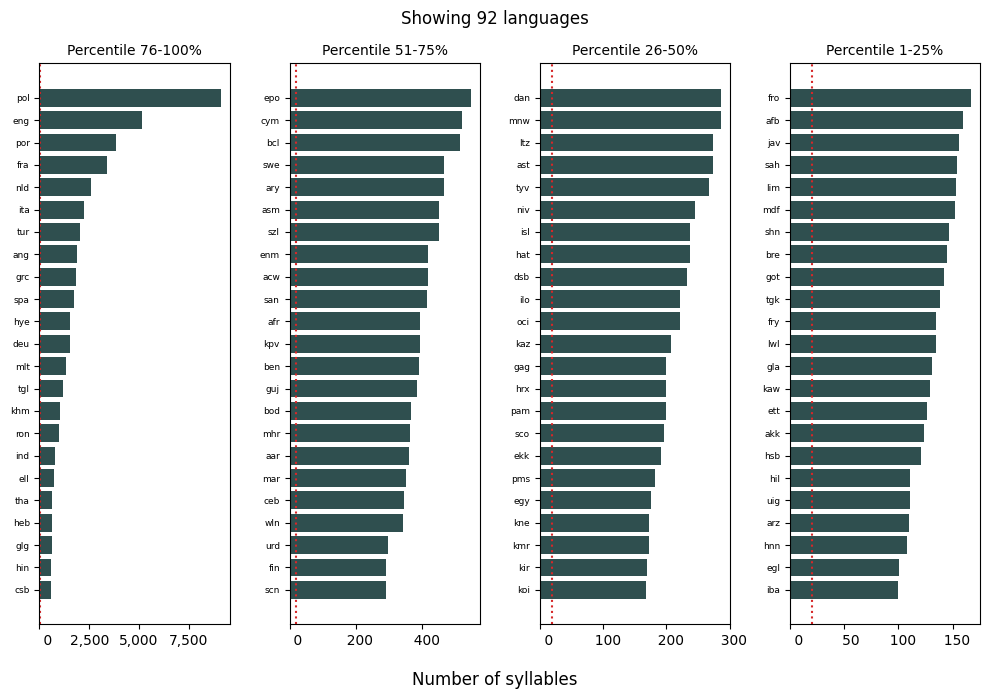

In [17]:
data = (
    sylls.group_by("iso639p3code")
    .len("n")
    .with_columns(
        qtile=pl.col("n").qcut(
            [0.25, 0.50, 0.75], labels=["1-25%", "26-50%", "51-75%", "76-100%"]
        )
    )
).sort("qtile", descending=True)

n_qtiles = len(data.unique("qtile"))
fig, axes = plt.subplots(1, n_qtiles, figsize=(10, 7))

for i, d in enumerate(data.partition_by("qtile")):
    lang, n, q = d.sort("n").iter_columns()
    ax = axes[i]
    ax.barh(lang, n, color=COLOR)
    ax.set_title(f"Percentile {q[0]}", fontsize=10)
    
    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))
    ax.axvline(20, linestyle="dotted", color="tab:red")
fig.suptitle(f"Showing {len(data)} languages")
fig.supxlabel("Number of syllables")
fig.tight_layout()

### Syllable lengths

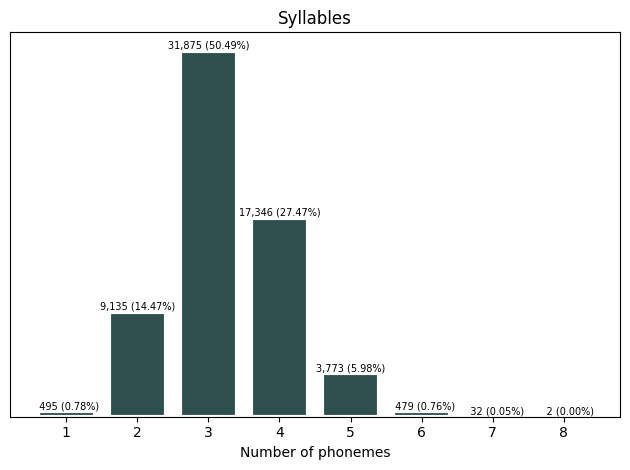

In [18]:
fig, ax = plt.subplots(1, 1)
labels, values =sylls["n_phon"].value_counts().iter_columns()
value_labels = [f"{v:5,d} ({v / sum(values):.2%})" for v in values]
p = ax.bar(labels, values, color=COLOR, edgecolor="white", linewidth=3)
ax.bar_label(p, value_labels, fontsize=7)
ax.set_title(label)
ax.set_yticks([])
ax.set_xlabel("Number of phonemes")
fig.tight_layout()

### Syllabic structures

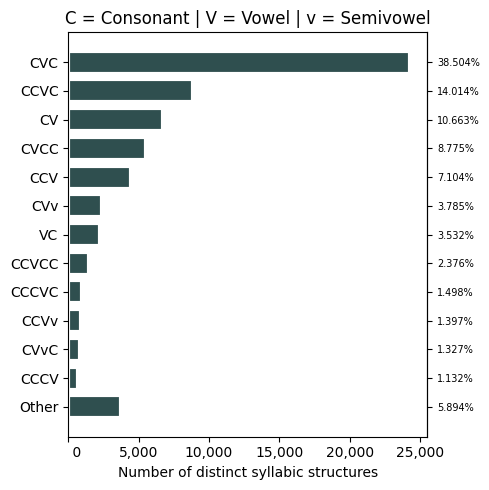

In [19]:
data = (
    sylls.group_by("struct")
    .len("n")
    .sort("n")
    .with_columns(
        struct=pl.when(pl.col("n") < (0.01 * len(sylls))).then(pl.lit("Other")).otherwise("struct"),
    )
    .group_by("struct")
    .agg(n=pl.col("n").sum())
    .sort("n")
    .with_columns(
        prop=pl.col("n") / pl.col("n").sum(),
        order=pl.when(pl.col("struct") == "Other").then(1).otherwise(0),
    )
    .sort(["order", "prop"], descending=[True, False])
)


fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.barh(data["struct"], data["n"], color=COLOR, edgecolor="white", linewidth=3)
ax.set_title("C = Consonant | V = Vowel | v = Semivowel")
ax.set_xlabel("Number of distinct syllabic structures")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):5,d}"))

ticks = ax.get_yticks()
labels = [f"{n:.3%}" for n in data["prop"]]
ax2 = ax.secondary_yaxis("right")
ax2.set_yticks(ticks)
ax2.set_yticklabels(labels, ha="left")
ax2.tick_params(axis="y", labelsize=7)

fig.tight_layout()

### Sonority sequencing principle

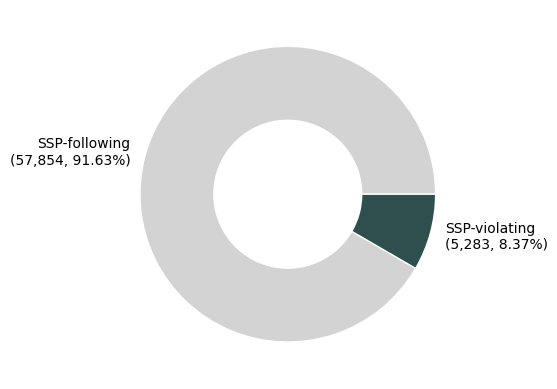

In [20]:
data = sylls.select(["iso639p3code", "is_ssp"]).get_column("is_ssp").value_counts()
values = data["count"]
labels = [
    f"{'SSP-following' if s else 'SSP-violating'}\n({n:,}, {n / sum(values):.2%})"
    for s, n in data.iter_rows()
]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

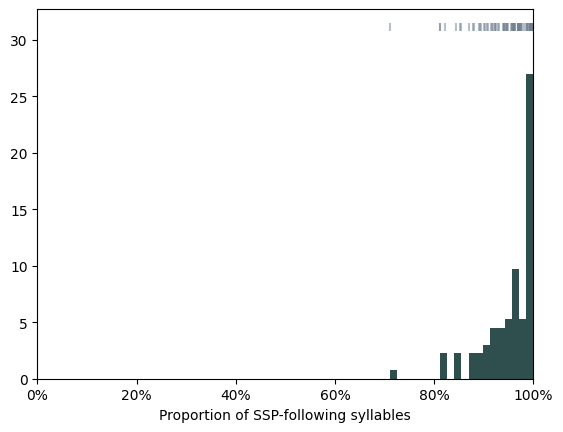

In [21]:
data = sylls.group_by("iso639p3code").agg(pl.col("is_ssp").mean())

fig, ax = plt.subplots(1, 1)
p = ax.hist(data["is_ssp"], density=True, histtype="stepfilled", bins=20, lw=3, color=COLOR)
_, ymax = ax.get_ylim()
ax.scatter(data["is_ssp"], [ymax + (ymax*0.1)] * len(data), marker="|", c="slategrey", alpha = 0.5)

ax.set_xlabel("Proportion of SSP-following syllables")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))

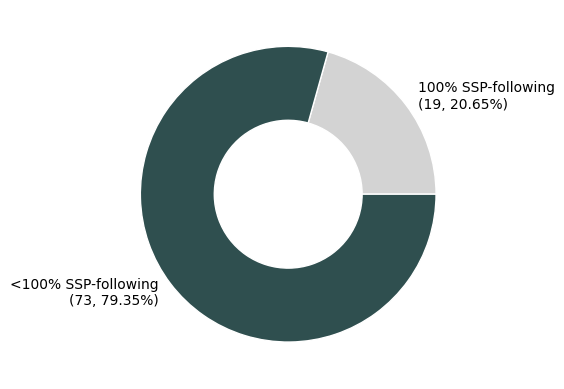

In [22]:
data = (
    (
        sylls.group_by("iso639p3code")
        .agg(pl.col("is_ssp").mean(), n=pl.len())
        .sort("is_ssp", descending=False)
        .with_columns(is_ssp=pl.when(pl.col("is_ssp") == 1).then(1).otherwise(0))
    )
    .get_column("is_ssp")
    .value_counts()
)

values = data["count"]
labels = [
    f"{'100% SSP-following' if s else '<100% SSP-following'}\n({n:,}, {n / sum(values):.2%})"
    for s, n in data.iter_rows()
]

fig, ax = plt.subplots(1, 1)
p = ax.pie(
    values,
    labels=labels,
    radius=1,
    wedgeprops=dict(width=0.5, edgecolor="w"),
    colors=["lightgrey", COLOR],
)

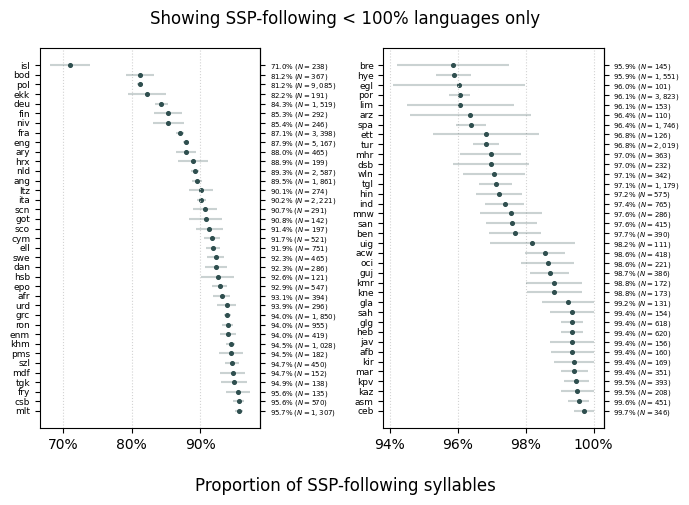

In [23]:
data = (
    sylls.group_by("iso639p3code")
    .agg(pl.col("is_ssp").mean(), n=pl.len())
    .filter(pl.col("is_ssp") != 1)
    .with_columns(se=((pl.col("is_ssp") * (1 - pl.col("is_ssp"))) / pl.col("n")).sqrt())
    .with_columns(
        qtile=pl.col("is_ssp").qcut([0.5], labels=["Bottom half", "Top half"])
    )
    .sort(["qtile", "is_ssp"], descending=[False, True])
    .partition_by("qtile", as_dict=True)
)


fig, axes = plt.subplots(1, len(data), figsize=(7, 5))
for i, (k, d) in enumerate(data.items()):
    ax = axes[i]
    dist_to_limit = d["is_ssp"] - 1
    yerr_clipped = np.maximum(d["se"], dist_to_limit)
    
    ax.errorbar(
        d["is_ssp"],
        d["iso639p3code"],
        xerr=yerr_clipped,
        c=COLOR,
        alpha=1 / 4,
        linestyle="None",
    )
    ax.scatter(d["is_ssp"], d["iso639p3code"], c=COLOR, s=7)

    ax.tick_params(axis="y", labelsize=6.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))
    ax.xaxis.grid(True, color="lightgrey", linestyle=":")

    ticks = ax.get_yticks()
    labels = [f"{p:.1%} ($N={n:5,d}$)" for p, n in zip(d["is_ssp"], d["n"])]
    ax2 = ax.secondary_yaxis("right")
    ax2.set_yticks(ticks)
    ax2.set_yticklabels(labels, ha="left")
    ax2.tick_params(axis="y", labelsize=5)

fig.suptitle("Showing SSP-following < 100% languages only")
fig.supxlabel("Proportion of SSP-following syllables")
fig.tight_layout()

List of languages with 100% SSP prevalence:

In [24]:
data = (
    sylls.group_by("iso639p3code")
    .agg(pl.col("is_ssp").mean(), n=pl.len())
    .filter(pl.col("is_ssp")==1)
)
data

iso639p3code,is_ssp,n
str,f64,u32
"""tha""",1.0,632
"""egy""",1.0,175
"""bcl""",1.0,516
"""fro""",1.0,167
"""iba""",1.0,100
…,…,…
"""shn""",1.0,147
"""hat""",1.0,237
"""lwl""",1.0,135


### SSP by number of observations

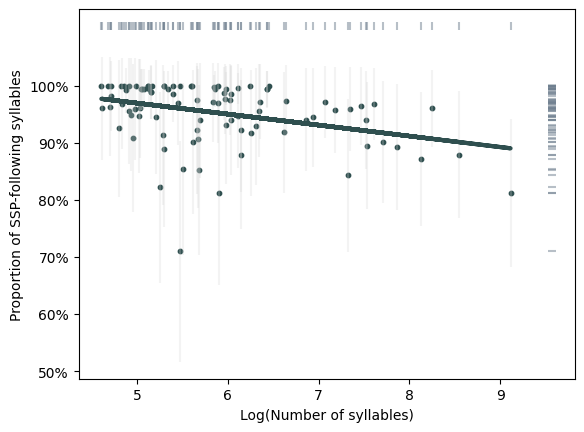

In [25]:
data = (
    sylls.group_by(["iso639p3code"])
    .agg(pl.col("is_ssp").mean(), n=pl.len().log())
    .with_columns(se=((pl.col("is_ssp") * (1 - pl.col("is_ssp"))) / pl.col("n")).sqrt())
)


fig, ax = plt.subplots(1, 1)
ax.scatter(data["n"], data["is_ssp"], color=COLOR, s=10)
dist_to_limit = data["is_ssp"] - 1
yerr_clipped = np.maximum(data["se"], dist_to_limit)
ax.errorbar(
    data["n"],
    data["is_ssp"],
    yerr=yerr_clipped,
    c="lightgrey",
    alpha=1 / 4,
    linestyle="None",
)

coef = np.polyfit(data["n"].to_list(), data["is_ssp"].to_list(), 1)
fit = np.poly1d(coef)
ax.plot(data["n"], fit(data["n"]), lw=3, c=COLOR)
ax.set_xlabel("Log(Number of syllables)")
ax.set_ylabel("Proportion of SSP-following syllables")

_, ymax = ax.get_ylim()
ax.scatter(
    data["n"], [ymax + (ymax * 0.025)] * len(data), marker="|", c="slategrey", alpha=0.5
)

_, xmax = ax.get_xlim()
ax.scatter(
    [xmax + (xmax * 0.025)] * len(data),
    data["is_ssp"],
    marker="_",
    c="slategrey",
    alpha=0.5,
)

ticks = np.linspace(0.5, 1, 6)
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:.0%}" for t in ticks])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:.0%}"))


## SSP and frequency

Text(0.5, 0.98, 'Ranked lexical frequency (Zipf)')

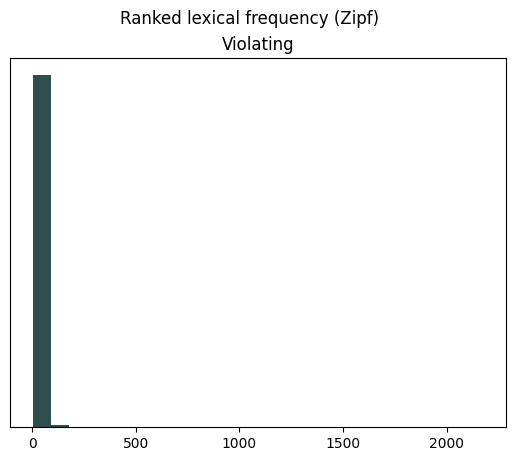

In [29]:
data = (
    sylls.select(["iso639p3code", "syll", "freq", "is_ssp"])
    .filter(pl.col("freq") != 0)
    .drop_nulls()
    .sort("is_ssp", descending=True)
)

colors = {True: COLOR, False: "lightgrey"}
fig, ax = plt.subplots(1, 1)
ax.hist(
        d["freq"], bins=25, color=COLOR, density=True, histtype="stepfilled"
    )
ax.set_title("Following" if k[0] else "Violating")
ax.set_yticklabels([])
ax.set_yticks([])
fig.suptitle("Ranked lexical frequency (Zipf)")

Text(0.5, 0.98, 'Ranked lexical frequency (Zipf)')

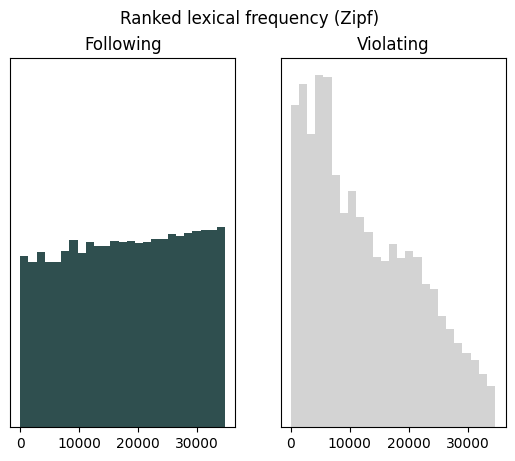

In [26]:
data = (
    sylls.select(["iso639p3code", "syll", "freq", "is_ssp"])
    .filter(pl.col("freq") != 0)
    .drop_nulls()
    .sort("is_ssp", descending=True)
    .with_columns(rank=pl.col("freq").rank())
)

colors = {True: COLOR, False: "lightgrey"}
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True)
for i, (k, d) in enumerate(data.partition_by("is_ssp", as_dict=True).items()):
    ax = axes[i]
    zorder = 0 if k[0] else 0
    ax.hist(
        d["rank"], bins=25, zorder=zorder, color=colors[k[0]], density=True, histtype="stepfilled"
    )
    ax.set_title("Following" if k[0] else "Violating")
    ax.set_yticklabels([])
    ax.set_yticks([])
fig.suptitle("Ranked lexical frequency (Zipf)")

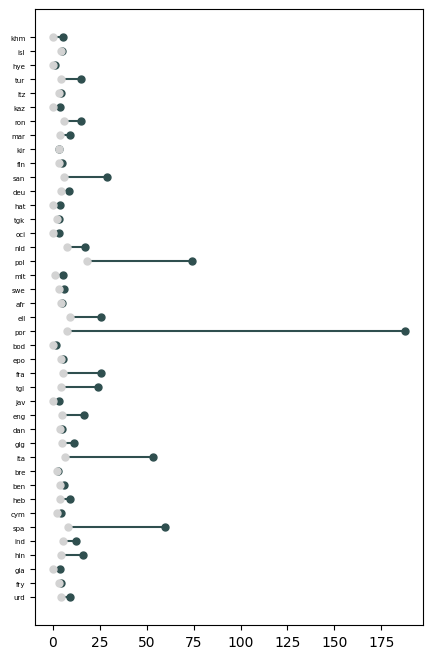

In [27]:
data = (
    sylls.select(["iso639p3code", "syll", "freq", "is_ssp"])
    .filter(pl.col("freq") != 0)
    .drop_nulls()
    .group_by(["iso639p3code", "is_ssp"])
    .agg(pl.col("freq").mean())
    .pivot(on="is_ssp", index=["iso639p3code"], values="freq").fill_null(0)
    .unpivot(index="iso639p3code",on=["true", "false"], variable_name="is_ssp", value_name="freq")
    .with_columns(pl.col("is_ssp")=="true")
)

data_ssp = data.filter(pl.col("is_ssp"))
data_no_ssp=data.filter(~pl.col("is_ssp"))

colors = {True: COLOR, False: "lightgrey"}
fig, ax = plt.subplots(1, 1, figsize=(5, 8))
ax.hlines(y=data_ssp["iso639p3code"], xmin=data_ssp["freq"], xmax = data_no_ssp["freq"], colors=[COLOR if a > b else "lightgrey" for a, b in zip(data_ssp["freq"], data_no_ssp["freq"])])

for k, d in data.partition_by("is_ssp", as_dict=True).items():
    is_ssp = k[0]
    label = "Following" if is_ssp else "Violating"
    zorder = 0 if is_ssp else 1
    ax.scatter(d["freq"], d["iso639p3code"], c=colors[is_ssp], s=25, zorder=10)
    ax.tick_params(axis="y", labelsize=5)
# fig.legend()


## The causal structure of the research question

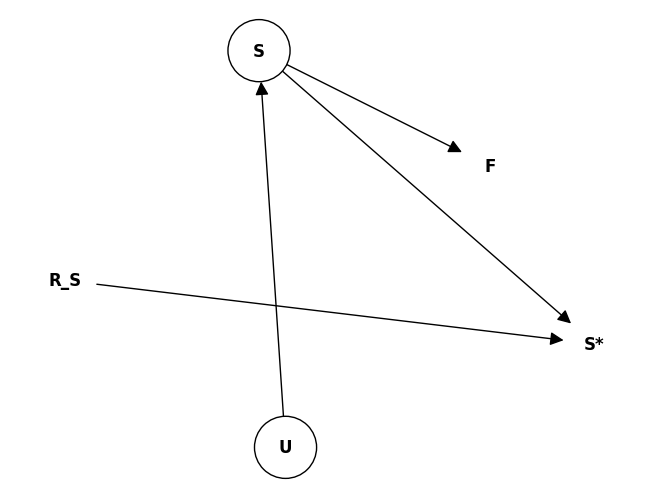

In [59]:
# Create the Directed Graph
G = nx.DiGraph()

# Add nodes
nodes = ['S', 'S*', 'U', "F", "R_S"]
G.add_nodes_from(nodes)

# Add edges: S-S*, S-F, U-S
edges = [('S', 'S*'), ('S', 'F'), ('U', 'S'), ("R_S", "S*")]
G.add_edges_from(edges)

# Define node border colors based on requirements
# Order: F, S, S*, U
# F and S* should be black
# S and U should have no color ('none')
node_border_colors = ['black', 'none', 'black', 'none', "none"]

border_widths = [1, 0, 1, 0, 0]

# Define layout (using spring layout for a clean look)
pos = nx.arf_layout(G)

# Draw the graph
nx.draw(G, pos, 
        with_labels=True, 
        node_size=2000, 
        node_color='white',       # Fill color of nodes
        edgecolors=node_border_colors, # Color of the node borders
        linewidths=border_widths,     # Width of the node borders
        arrowsize=20, 
        font_weight='bold',
        font_size=12)




In [32]:
words.select(["iso639p3code", "lang", "family_id", "phon", "syll"]).sample(100).head(100)

iso639p3code,lang,family_id,phon,syll
str,str,str,str,list[str]
"""grc""","""Ionic-Attic Ancient Greek""","""Indo-European""","""no.çeˈlis""","[""no"", ""çe"", ""lis""]"
"""spa""","""Spanish""","""Indo-European""","""ˌfotoeleɡtɾisiˈdad""","[""fotoeleɡtɾisi"", ""dad""]"
"""por""","""Portuguese""","""Indo-European""","""maˈli""","[""ma"", ""li""]"
"""fin""","""Finnish""","""Uralic""","""ˈhei̯næˌkertːu""","[""hei̯næ"", ""kertːu""]"
"""hye""","""Eastern Armenian""","""Indo-European""","""hɑsɑɾɑˈɡɑd͡z""","[""hɑsɑɾɑ"", ""ɡɑd͡z""]"
…,…,…,…,…
"""pol""","""Polish""","""Indo-European""","""pɔ.dru.ʐɔˈva.wɘ.bɘɕ.t͡ɕɛ""","[""pɔ"", ""dru"", … ""t͡ɕɛ""]"
"""spa""","""Spanish""","""Indo-European""","""ˈmwon""","[""mwon""]"
"""nci""","""Classical Nahuatl""","""Uto-Aztecan""","""miːlli""","[""miːlli""]"


In [31]:
sylls.select(["iso639p3code", "lang", "family_id", "syll", "struct", "sonority", "is_ssp"]).sample(100).head(100)

iso639p3code,lang,family_id,syll,struct,sonority,is_ssp
str,str,str,str,str,list[str],bool
"""cym""","""Welsh""","""Indo-European""","""rjɔl""","""CCVC""","[""6"", ""7"", … ""6""]",true
"""por""","""Portuguese""","""Indo-European""","""piʃ""","""CVC""","[""1"", ""8"", ""3""]",true
"""pol""","""Polish""","""Indo-European""","""zɒ""","""CV""","[""4"", ""9""]",true
"""por""","""Portuguese""","""Indo-European""","""ʃa""","""CV""","[""3"", ""9""]",true
"""hye""","""Eastern Armenian""","""Indo-European""","""kɑv""","""CVC""","[""1"", ""9"", ""4""]",true
…,…,…,…,…,…,…
"""oci""","""Occitan""","""Indo-European""","""suj""","""CVv""","[""3"", ""8"", ""7""]",true
"""fra""","""French""","""Indo-European""","""bʁabl""","""CCVCC""","[""2"", ""4"", … ""6""]",false
"""mhr""","""Eastern Mari""","""Uralic""","""jyɾ""","""CVC""","[""7"", ""8"", ""6""]",true
